<a href="https://colab.research.google.com/github/WeDynamics/pxl/blob/main/upscaller-google-colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#@title 1. Install Dependencies & Load Model
!pip install -q spandrel

import os
import math
import urllib.request
import torch
import torch.nn.functional as F
import numpy as np
from PIL import Image, ImageOps
from spandrel import ModelLoader, ImageModelDescriptor

# Pilihan Model
MODEL_NAME = "RealESRGAN_x4plus_anime_6B (Anime/Ilustrasi 4x)" #@param ["RealESRGAN_x4plus (Foto Umum 4x)", "RealESRGAN_x4plus_anime_6B (Anime/Ilustrasi 4x)", "RealESRGAN_x2plus (Foto Umum 2x)"]

MODEL_URLS = {
    "RealESRGAN_x4plus (Foto Umum 4x)": (
        "RealESRGAN_x4plus.pth",
        "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.1.0/RealESRGAN_x4plus.pth"
    ),
    "RealESRGAN_x4plus_anime_6B (Anime/Ilustrasi 4x)": (
        "RealESRGAN_x4plus_anime_6B.pth",
        "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.2.4/RealESRGAN_x4plus_anime_6B.pth"
    ),
    "RealESRGAN_x2plus (Foto Umum 2x)": (
        "RealESRGAN_x2plus.pth",
        "https://github.com/xinntao/Real-ESRGAN/releases/download/v0.2.1/RealESRGAN_x2plus.pth"
    ),
}

os.makedirs("weights", exist_ok=True)
filename, url = MODEL_URLS[MODEL_NAME]
model_path = os.path.join("weights", filename)

if not os.path.exists(model_path):
    print(f"Mengunduh model {filename}...")
    urllib.request.urlretrieve(url, model_path)
    print("Unduhan selesai!")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_half = device.type == "cuda"

model = ModelLoader().load_from_file(model_path)
assert isinstance(model, ImageModelDescriptor), "Model tidak valid untuk image-to-image."
model.to(device).eval()

if use_half and model.supports_half:
    model.half()
else:
    use_half = False

print(f"Model siap digunakan: {filename} | Skala: {model.scale}x | Device: {device} | FP16: {use_half}")

Mengunduh model RealESRGAN_x4plus_anime_6B.pth...
Unduhan selesai!
Model siap digunakan: RealESRGAN_x4plus_anime_6B.pth | Skala: 4x | Device: cuda | FP16: True


Silakan pilih gambar yang ingin di-upscale (bisa lebih dari 1):


Saving Logo R Neon dengan Panel Tumpuk.webp to Logo R Neon dengan Panel Tumpuk.webp

Memproses: Logo R Neon dengan Panel Tumpuk.webp...
Selesai! Resolusi: 1254x1254 -> 5016x5016
Disimpan di: results/Logo R Neon dengan Panel Tumpuk_upscaled_4x.png


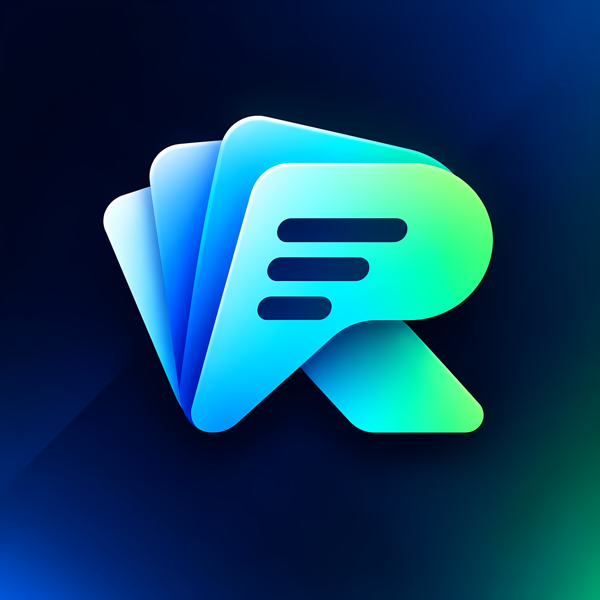

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
#@title 2. Upload & Upscale Gambar
from google.colab import files
from IPython.display import display
import io

TILE_SIZE = 512 #@param {type:"slider", min:128, max:1024, step:128}
OUTPUT_FORMAT = "PNG" #@param ["PNG", "JPEG"]
AUTO_DOWNLOAD = True #@param {type:"boolean"}

def upscale_tensor(model, img_tensor, tile_size=512, tile_pad=32):
    scale = model.scale
    _, c, h, w = img_tensor.shape

    def run_model(x):
        _, _, xh, xw = x.shape
        pad_h = (16 - xh % 16) % 16
        pad_w = (16 - xw % 16) % 16
        if pad_h > 0 or pad_w > 0:
            x = F.pad(x, (0, pad_w, 0, pad_h), mode="replicate")
        with torch.no_grad():
            out = model(x)
        return out[:, :, :xh * scale, :xw * scale]

    if tile_size <= 0 or (h <= tile_size and w <= tile_size):
        return run_model(img_tensor).cpu()

    output = torch.zeros((1, c, h * scale, w * scale), dtype=torch.float32, device="cpu")
    tiles_x = math.ceil(w / tile_size)
    tiles_y = math.ceil(h / tile_size)

    for y in range(tiles_y):
        for x in range(tiles_x):
            input_start_x = x * tile_size
            input_end_x = min(input_start_x + tile_size, w)
            input_start_y = y * tile_size
            input_end_y = min(input_start_y + tile_size, h)

            input_start_x_pad = max(input_start_x - tile_pad, 0)
            input_end_x_pad = min(input_end_x + tile_pad, w)
            input_start_y_pad = max(input_start_y - tile_pad, 0)
            input_end_y_pad = min(input_end_y + tile_pad, h)

            input_tile = img_tensor[:, :, input_start_y_pad:input_end_y_pad, input_start_x_pad:input_end_x_pad]
            output_tile = run_model(input_tile).float().cpu()

            output_start_x = input_start_x * scale
            output_end_x = input_end_x * scale
            output_start_y = input_start_y * scale
            output_end_y = input_end_y * scale

            tile_start_x = (input_start_x - input_start_x_pad) * scale
            tile_end_x = tile_start_x + (input_end_x - input_start_x) * scale
            tile_start_y = (input_start_y - input_start_y_pad) * scale
            tile_end_y = tile_start_y + (input_end_y - input_start_y) * scale

            output[:, :, output_start_y:output_end_y, output_start_x:output_end_x] = output_tile[
                :, :, tile_start_y:tile_end_y, tile_start_x:tile_end_x
            ]

    return output

os.makedirs("results", exist_ok=True)
print("Silakan pilih gambar yang ingin di-upscale (bisa lebih dari 1):")
uploaded = files.upload()

for name, data in uploaded.items():
    print(f"\nMemproses: {name}...")
    img = Image.open(io.BytesIO(data))
    img = ImageOps.exif_transpose(img)  # Jaga orientasi asli foto

    has_alpha = img.mode in ("RGBA", "LA") or (img.mode == "P" and "transparency" in img.info)
    if has_alpha:
        img = img.convert("RGBA")
        alpha = img.getchannel("A")
        rgb_img = img.convert("RGB")
    else:
        rgb_img = img.convert("RGB")

    img_np = np.array(rgb_img).astype(np.float32) / 255.0
    img_tensor = torch.from_numpy(img_np).permute(2, 0, 1).unsqueeze(0).to(device)
    if use_half:
        img_tensor = img_tensor.half()

    out_tensor = upscale_tensor(model, img_tensor, tile_size=TILE_SIZE)
    out_np = out_tensor.squeeze(0).permute(1, 2, 0).clamp(0, 1).numpy()
    out_img = Image.fromarray((out_np * 255.0).round().astype(np.uint8))

    if has_alpha:
        alpha_up = alpha.resize(out_img.size, Image.Resampling.LANCZOS)
        out_img.putalpha(alpha_up)

    base_name = os.path.splitext(name)[0]
    ext = "png" if (OUTPUT_FORMAT == "PNG" or has_alpha) else "jpg"
    out_path = os.path.join("results", f"{base_name}_upscaled_{model.scale}x.{ext}")

    if ext == "jpg":
        out_img.save(out_path, "JPEG", quality=95)
    else:
        out_img.save(out_path, "PNG")

    print(f"Selesai! Resolusi: {img.size[0]}x{img.size[1]} -> {out_img.size[0]}x{out_img.size[1]}")
    print(f"Disimpan di: {out_path}")

    # Tampilkan preview kecil di output Colab
    preview = out_img.copy()
    preview.thumbnail((600, 600))
    display(preview)

    if AUTO_DOWNLOAD:
        files.download(out_path)